# 🎾 ATP Serve Impact Analysis

**Question :** quels indicateurs de service différencient réellement les vainqueurs des perdants sur le circuit ATP, et leur importance dépend-elle de la surface ?

**Données :** tous les matchs ATP en simple de la saison 2023 (`atp_matches_2023.csv`) et la fiche des joueurs (`atp_players.csv`).

**Plan du notebook**

1. Chargement et exploration
2. Nettoyage
3. Création des indicateurs de service
4. Analyse 1 : vainqueurs contre perdants
5. Analyse 2 : influence de la surface
6. Analyse 3 : les upsets
7. Serve Performance Score
8. Bonus : taille du joueur et aces
9. Conclusions

## 1. Chargement et exploration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)

DATA_DIR = "../data"
IMG_DIR = "../images"

In [2]:
# Style commun à tous les graphiques
WINNER_COLOR = "#2a78d6"   # bleu
LOSER_COLOR = "#eb6834"    # orange
BACKGROUND = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": BACKGROUND,
    "axes.facecolor": BACKGROUND,
    "savefig.facecolor": BACKGROUND,
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10,
    "text.color": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": INK_SECONDARY,
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "ytick.left": False,
    "legend.frameon": False,
})


def label_bars(ax, bars, fmt="{:.1f}%"):
    """Écrit la valeur au-dessus de chaque barre."""
    for bar in bars:
        ax.annotate(fmt.format(bar.get_height()),
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, color=INK_SECONDARY)


def winner_loser_bars(ax, categories, winner_values, loser_values):
    """Barres groupées Vainqueur / Perdant (valeurs déjà en %)."""
    x = np.arange(len(categories))
    width = 0.36
    b1 = ax.bar(x - width / 2, winner_values, width, color=WINNER_COLOR,
                label="Vainqueur", edgecolor=BACKGROUND, linewidth=1.5)
    b2 = ax.bar(x + width / 2, loser_values, width, color=LOSER_COLOR,
                label="Perdant", edgecolor=BACKGROUND, linewidth=1.5)
    label_bars(ax, b1)
    label_bars(ax, b2)
    ax.set_xticks(x, categories)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")

In [3]:
df = pd.read_csv(f"{DATA_DIR}/atp_matches_2023.csv")
df.head()

,tourney_id,tourney_name,surface,draw_size,tourney_level,tourney_date,match_num,winner_id,winner_seed,winner_entry,winner_name,winner_hand,winner_ht,winner_ioc,winner_age,loser_id,loser_seed,loser_entry,loser_name,loser_hand,loser_ht,loser_ioc,loser_age,score,best_of,round,minutes,w_ace,w_df,w_svpt,w_1stIn,w_1stWon,w_2ndWon,w_SvGms,w_bpSaved,w_bpFaced,l_ace,l_df,l_svpt,l_1stIn,l_1stWon,l_2ndWon,l_SvGms,l_bpSaved,l_bpFaced,winner_rank,winner_rank_points,loser_rank,loser_rank_points
0,2023-9900,United Cup,Hard,18,A,20230102,300,126203,3.000,NaN,Taylor Fritz,R,193.000,USA,25.100,126610,5.000,NaN,Matteo Berrettini,R,196.000,ITA,26.700,7-6(4) 7-6(6),3,F,135.000,15.000,2.000,85.000,52.000,45.000,16.000,12.000,0.000,0.000,7.000,2.000,97.000,62.000,47.000,15.000,12.000,9.000,9.000,9.000,3355.000,16.000,2375.000
1,2023-9900,United Cup,Hard,18,A,20230102,299,126207,NaN,NaN,Frances Tiafoe,R,188.000,USA,24.900,207518,NaN,NaN,Lorenzo Musetti,R,185.000,ITA,20.800,6-2 0-0 RET,3,F,34.000,3.000,1.000,27.000,19.000,15.000,3.000,4.000,3.000,3.000,0.000,0.000,21.000,12.000,8.000,3.000,4.000,1.000,3.000,19.000,2000.000,23.000,1865.000
2,2023-9900,United Cup,Hard,18,A,20230102,296,126203,3.000,NaN,Taylor Fritz,R,193.000,USA,25.100,128034,2.000,NaN,Hubert Hurkacz,R,196.000,POL,25.800,7-6(5) 7-6(5),3,SF,104.000,11.000,0.000,80.000,50.000,44.000,19.000,12.000,4.000,4.000,17.000,1.000,82.000,62.000,51.000,7.000,12.000,2.000,2.000,9.000,3355.000,10.000,2905.000
3,2023-9900,United Cup,Hard,18,A,20230102,295,126207,NaN,NaN,Frances Tiafoe,R,188.000,USA,24.900,200390,NaN,NaN,Kacper Zuk,R,183.000,POL,23.900,6-3 6-3,3,SF,79.000,5.000,4.000,61.000,37.000,31.000,11.000,9.000,5.000,5.000,3.000,3.000,68.000,41.000,26.000,12.000,9.000,6.000,9.000,19.000,2000.000,245.000,220.000
4,2023-9900,United Cup,Hard,18,A,20230102,292,126774,1.000,NaN,Stefanos Tsitsipas,R,193.000,GRE,24.300,126610,5.000,NaN,Matteo Berrettini,R,196.000,ITA,26.700,4-6 7-6(2) 6-4,3,SF,155.000,9.000,1.000,98.000,52.000,43.000,28.000,16.000,1.000,2.000,7.000,2.000,89.000,58.000,48.000,18.000,16.000,1.000,2.000,4.000,5550.000,16.000,2375.000


In [4]:
print(f"Nombre de matchs    : {df.shape[0]}")
print(f"Nombre de variables : {df.shape[1]}")
df.info()

Nombre de matchs    : 2242
Nombre de variables : 49
<class 'pandas.DataFrame'>
RangeIndex: 2242 entries, 0 to 2241
Data columns (total 49 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   tourney_id          2242 non-null   str    
 1   tourney_name        2242 non-null   str    
 2   surface             2242 non-null   str    
 3   draw_size           2242 non-null   int64  
 4   tourney_level       2242 non-null   str    
 5   tourney_date        2242 non-null   int64  
 6   match_num           2242 non-null   int64  
 7   winner_id           2242 non-null   int64  
 8   winner_seed         947 non-null    float64
 9   winner_entry        367 non-null    str    
 10  winner_name         2242 non-null   str    
 11  winner_hand         2242 non-null   str    
 12  winner_ht           2123 non-null   float64
 13  winner_ioc          2242 non-null   str    
 14  winner_age          2242 non-null   float64
 15  loser_id      

In [5]:
serve_stats = ["ace", "df", "svpt", "1stIn", "1stWon", "2ndWon", "bpSaved", "bpFaced"]
serve_cols = [f"{side}_{stat}" for side in ("w", "l") for stat in serve_stats]

df[serve_cols + ["winner_rank", "loser_rank"]].describe().T

,count,mean,std,min,25%,50%,75%,max
w_ace,2129.000,6.667,5.056,0.000,3.000,6.000,9.000,42.000
w_df,2129.000,2.568,2.215,0.000,1.000,2.000,4.000,15.000
w_svpt,2129.000,79.151,29.216,5.000,58.000,75.000,95.000,228.000
w_1stIn,2129.000,49.970,19.612,3.000,36.000,47.000,60.000,142.000
w_1stWon,2129.000,37.729,13.968,1.000,28.000,35.000,45.000,100.000
w_2ndWon,2129.000,16.202,6.533,1.000,12.000,15.000,20.000,45.000
w_bpSaved,2129.000,3.444,3.063,0.000,1.000,3.000,5.000,22.000
w_bpFaced,2129.000,4.976,4.013,0.000,2.000,4.000,7.000,26.000
l_ace,2129.000,5.215,4.934,0.000,2.000,4.000,7.000,44.000
l_df,2129.000,3.242,2.614,0.000,1.000,3.000,4.000,25.000


In [6]:
missing = df.isna().sum()
missing[missing > 0].sort_values(ascending=False)

winner_entry          1875
loser_entry           1693
loser_seed            1655
winner_seed           1295
minutes                232
loser_ht               223
winner_ht              119
w_ace                  113
w_df                   113
w_svpt                 113
w_1stWon               113
w_1stIn                113
w_2ndWon               113
w_SvGms                113
l_2ndWon               113
w_bpSaved              113
w_bpFaced              113
l_ace                  113
l_df                   113
l_svpt                 113
l_1stIn                113
l_1stWon               113
l_bpSaved              113
l_SvGms                113
l_bpFaced              113
loser_rank_points       21
loser_rank              21
winner_rank_points      11
winner_rank             11
loser_age                4
dtype: int64

In [7]:
print("Doublons (lignes identiques)       :", df.duplicated().sum())
print("Doublons (tournoi + n° de match)   :", df.duplicated(["tourney_id", "match_num"]).sum())
print()
print(df["surface"].value_counts())

Doublons (lignes identiques)       : 0
Doublons (tournoi + n° de match)   : 0

surface
Hard     1040
Clay      878
Grass     324
Name: count, dtype: int64


In [8]:
# Les 113 matchs sans statistiques de service : surtout la Coupe Davis (niveau "D")
df[df["w_svpt"].isna()]["tourney_level"].value_counts()

tourney_level
D    96
A    11
M     5
G     1
Name: count, dtype: int64

**Ce qu'on retient de l'exploration**

- 2 242 matchs et 49 variables, aucun doublon.
- Les trois surfaces attendues sont présentes : Hard (1 040), Clay (878), Grass (324). Il n'y a pas de Carpet en 2023.
- Les statistiques de service manquent pour 113 matchs (toujours toutes ensemble), dont 96 en Coupe Davis.
- Quelques classements manquent (11 vainqueurs, 21 perdants), ce qui ne concerne que l'analyse des upsets.
- Les colonnes `seed`, `entry` et `minutes` ont beaucoup de valeurs manquantes, mais elles ne servent pas à l'analyse.

## 2. Nettoyage

Trois règles simples :

1. **Supprimer les matchs sans statistiques de service** : ils ne peuvent pas être analysés.
2. **Supprimer les abandons, forfaits et disqualifications** (`RET`, `W/O`, `DEF` dans le score). Le vainqueur n'a pas « gagné au service » : son adversaire s'est arrêté, souvent blessé. Garder ces matchs fausserait la comparaison.
3. **Garder uniquement Hard, Clay et Grass** et vérifier qu'il y a au moins un point joué au service.

In [9]:
n_start = len(df)

has_stats = df[serve_cols].notna().all(axis=1)
incomplete_match = df["score"].str.contains("RET|W/O|DEF", na=False)

df_clean = df[has_stats & ~incomplete_match].copy()
df_clean = df_clean[df_clean["surface"].isin(["Hard", "Clay", "Grass"])]
df_clean = df_clean[(df_clean["w_svpt"] > 0) & (df_clean["l_svpt"] > 0)]

print(f"Matchs sans statistiques de service : {(~has_stats).sum()}")
print(f"Abandons / forfaits (avec stats)    : {(has_stats & incomplete_match).sum()}")
print(f"Matchs conservés                    : {len(df_clean)} sur {n_start} ({len(df_clean) / n_start:.1%})")
print()
print(df_clean["surface"].value_counts())

Matchs sans statistiques de service : 113
Abandons / forfaits (avec stats)    : 54
Matchs conservés                    : 2075 sur 2242 (92.6%)

surface
Hard     921
Clay     832
Grass    322
Name: count, dtype: int64


In [10]:
# Toutes les statistiques utilisées doivent être numériques
df_clean[serve_cols + ["winner_rank", "loser_rank"]].dtypes.value_counts()

float64    18
Name: count, dtype: int64

In [11]:
df_service = df_clean[
    [
        "surface",
        "winner_id", "winner_name", "winner_rank",
        "loser_id", "loser_name", "loser_rank",
    ]
    + serve_cols
].reset_index(drop=True)

df_service.head()

,surface,winner_id,winner_name,winner_rank,loser_id,loser_name,loser_rank,w_ace,w_df,w_svpt,w_1stIn,w_1stWon,w_2ndWon,w_bpSaved,w_bpFaced,l_ace,l_df,l_svpt,l_1stIn,l_1stWon,l_2ndWon,l_bpSaved,l_bpFaced
0,Hard,126203,Taylor Fritz,9.000,126610,Matteo Berrettini,16.000,15.000,2.000,85.000,52.000,45.000,16.000,0.000,0.000,7.000,2.000,97.000,62.000,47.000,15.000,9.000,9.000
1,Hard,126203,Taylor Fritz,9.000,128034,Hubert Hurkacz,10.000,11.000,0.000,80.000,50.000,44.000,19.000,4.000,4.000,17.000,1.000,82.000,62.000,51.000,7.000,2.000,2.000
2,Hard,126207,Frances Tiafoe,19.000,200390,Kacper Zuk,245.000,5.000,4.000,61.000,37.000,31.000,11.000,5.000,5.000,3.000,3.000,68.000,41.000,26.000,12.000,6.000,9.000
3,Hard,126774,Stefanos Tsitsipas,4.000,126610,Matteo Berrettini,16.000,9.000,1.000,98.000,52.000,43.000,28.000,1.000,2.000,7.000,2.000,89.000,58.000,48.000,18.000,1.000,2.000
4,Hard,207518,Lorenzo Musetti,23.000,208852,Stefanos Sakellaridis,803.000,2.000,1.000,41.000,25.000,18.000,12.000,1.000,1.000,2.000,1.000,43.000,26.000,15.000,5.000,4.000,9.000


## 3. Création des indicateurs de service

Les valeurs brutes (nombre d'aces, de doubles fautes…) dépendent de la longueur du match : un match en 5 sets produit mécaniquement plus d'aces. On travaille donc avec des **taux**.

| Indicateur | Formule |
|---|---|
| Taux d'aces | aces / points au service |
| Taux de doubles fautes | doubles fautes / points au service |
| % de premières balles | premières balles réussies / points au service |
| % de points gagnés sur 1re balle | points gagnés sur 1re / premières balles réussies |
| % de points gagnés sur 2e balle | points gagnés sur 2e / (points au service − premières balles réussies) |
| % de balles de break sauvées | balles de break sauvées / balles de break concédées |

Quand un joueur n'a concédé **aucune** balle de break, le taux de balles de break sauvées n'existe pas : on le laisse vide (`NaN`) plutôt que d'inventer une valeur.

In [12]:
for side in ("w", "l"):
    svpt = df_service[f"{side}_svpt"]
    first_in = df_service[f"{side}_1stIn"]
    second_attempts = svpt - first_in

    df_service[f"{side}_ace_rate"] = df_service[f"{side}_ace"] / svpt
    df_service[f"{side}_df_rate"] = df_service[f"{side}_df"] / svpt
    df_service[f"{side}_first_serve_in"] = first_in / svpt
    df_service[f"{side}_first_serve_win"] = df_service[f"{side}_1stWon"] / first_in
    df_service[f"{side}_second_serve_win"] = df_service[f"{side}_2ndWon"] / second_attempts
    # Division par zéro évitée : 0 balle de break concédée -> NaN
    df_service[f"{side}_bp_saved_rate"] = (
        df_service[f"{side}_bpSaved"] / df_service[f"{side}_bpFaced"].replace(0, np.nan)
    )

INDICATORS = {
    "ace_rate": "Taux d'aces",
    "df_rate": "Taux de doubles fautes",
    "first_serve_in": "% 1res balles",
    "first_serve_win": "% pts gagnés 1re balle",
    "second_serve_win": "% pts gagnés 2e balle",
    "bp_saved_rate": "% balles de break sauvées",
}

rate_cols = [f"{side}_{ind}" for ind in INDICATORS for side in ("w", "l")]
df_service[rate_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
w_ace_rate,2075.000,0.087,0.060,0.000,0.043,0.074,0.118,0.377
l_ace_rate,2075.000,0.062,0.049,0.000,0.025,0.050,0.086,0.373
w_df_rate,2075.000,0.032,0.024,0.000,0.014,0.028,0.045,0.155
l_df_rate,2075.000,0.040,0.030,0.000,0.019,0.035,0.055,0.215
w_first_serve_in,2075.000,0.631,0.073,0.349,0.581,0.633,0.678,0.929
l_first_serve_in,2075.000,0.615,0.071,0.373,0.566,0.615,0.661,0.854
w_first_serve_win,2075.000,0.766,0.080,0.508,0.713,0.767,0.820,1.000
l_first_serve_win,2075.000,0.665,0.092,0.214,0.609,0.671,0.727,0.936
w_second_serve_win,2075.000,0.565,0.103,0.278,0.500,0.559,0.632,0.909
l_second_serve_win,2075.000,0.461,0.099,0.100,0.400,0.464,0.526,0.824


In [13]:
print("Vainqueurs sans balle de break concédée :", df_service["w_bp_saved_rate"].isna().sum())
print("Perdants sans balle de break concédée   :", df_service["l_bp_saved_rate"].isna().sum())

Vainqueurs sans balle de break concédée : 176
Perdants sans balle de break concédée   : 3


Tous les taux sont bien compris entre 0 et 1. Fait marquant dès cette étape : **176 vainqueurs (8,5 %) n'ont concédé aucune balle de break**, contre seulement 3 perdants. Ne jamais être menacé sur son service est presque une garantie de victoire.

## 4. Analyse 1 : vainqueurs contre perdants

> Les vainqueurs servent-ils statistiquement mieux que les perdants ?

Pour chaque indicateur, on compare la moyenne des vainqueurs et celle des perdants. Comme les indicateurs n'ont pas la même échelle (8 % d'aces contre 77 % de points gagnés sur 1re balle), un écart brut ne suffit pas pour les classer. On ajoute donc une mesure plus parlante : **le pourcentage de matchs où le vainqueur fait strictement mieux que le perdant** sur cet indicateur. 50 % signifie que l'indicateur ne distingue pas du tout le vainqueur ; 100 % qu'il le distingue toujours.

In [14]:
rows = []
for ind, label in INDICATORS.items():
    w, l = df_service[f"w_{ind}"], df_service[f"l_{ind}"]
    both = w.notna() & l.notna()
    # Pour les doubles fautes, « faire mieux » = en faire moins
    winner_better = (w[both] < l[both]) if ind == "df_rate" else (w[both] > l[both])
    rows.append({
        "Indicateur": label,
        "Vainqueur (%)": 100 * w.mean(),
        "Perdant (%)": 100 * l.mean(),
        "Écart (pts)": 100 * (w.mean() - l.mean()),
        "Vainqueur meilleur (% des matchs)": 100 * winner_better.mean(),
    })

summary = pd.DataFrame(rows).set_index("Indicateur").round(1)
summary

,Vainqueur (%),Perdant (%),Écart (pts),Vainqueur meilleur (% des matchs)
Indicateur,,,,
Taux d'aces,8.700,6.200,2.500,63.000
Taux de doubles fautes,3.200,4.000,-0.800,56.700
% 1res balles,63.100,61.500,1.600,56.200
% pts gagnés 1re balle,76.600,66.500,10.100,81.800
% pts gagnés 2e balle,56.500,46.100,10.300,76.600
% balles de break sauvées,67.500,52.000,15.500,68.300


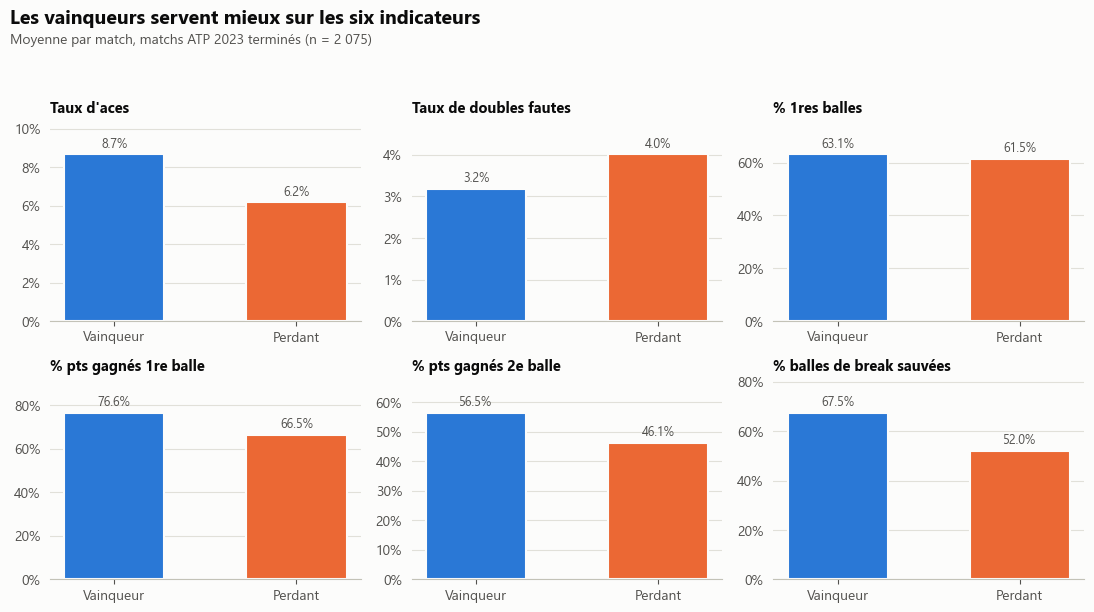

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))

for ax, (ind, label) in zip(axes.flat, INDICATORS.items()):
    values = [100 * df_service[f"w_{ind}"].mean(), 100 * df_service[f"l_{ind}"].mean()]
    bars = ax.bar(["Vainqueur", "Perdant"], values, width=0.55,
                  color=[WINNER_COLOR, LOSER_COLOR], edgecolor=BACKGROUND, linewidth=1.5)
    label_bars(ax, bars)
    ax.set_title(label, fontsize=10.5)
    ax.set_ylim(0, max(values) * 1.2)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")

fig.suptitle("Les vainqueurs servent mieux sur les six indicateurs",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.text(0.01, 0.925, "Moyenne par match, matchs ATP 2023 terminés (n = 2 075)",
         color=INK_SECONDARY, fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.91))
fig.savefig(f"{IMG_DIR}/serve_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

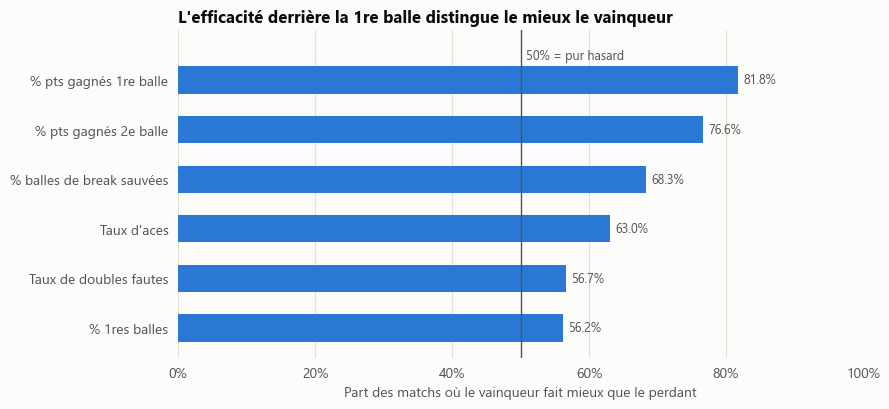

In [16]:
order = summary["Vainqueur meilleur (% des matchs)"].sort_values()

fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.barh(order.index, order.values, height=0.55, color=WINNER_COLOR)
ax.axvline(50, color=INK_SECONDARY, linewidth=1)
ax.set_ylim(-0.6, len(order))
ax.text(50.8, len(order) - 0.5, "50% = pur hasard", color=INK_SECONDARY, fontsize=9, va="center")
for bar in bars:
    ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.1f}%", va="center", fontsize=9, color=INK_SECONDARY)

ax.set_xlim(0, 100)
ax.grid(True, axis="x")
ax.grid(False, axis="y")
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="x", bottom=False)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_title("L'efficacité derrière la 1re balle distingue le mieux le vainqueur")
ax.set_xlabel("Part des matchs où le vainqueur fait mieux que le perdant")
fig.tight_layout()
fig.savefig(f"{IMG_DIR}/winner_better_share.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation**

- Les vainqueurs font mieux **en moyenne sur les six indicateurs**. Le service est clairement lié au résultat.
- Les deux écarts les plus nets concernent ce qui se passe **après** la mise en jeu : **+10 points** sur 1re balle (76,6 % contre 66,5 %) et **+10 points** sur 2e balle (56,5 % contre 46,1 %). Le vainqueur fait mieux sur la 1re balle dans **82 % des matchs** et sur la 2e dans **77 %**.
- Les **balles de break sauvées** suivent (68 %) : gagner, c'est aussi tenir son service dans les moments sous pression.
- Le **taux d'aces** (63 %) compte, mais beaucoup moins qu'on pourrait le croire : un gros serveur peut perdre si le reste ne suit pas.
- Le **pourcentage de premières balles** (56 %) et les **doubles fautes** (57 %) distinguent à peine mieux que le hasard. **Mettre beaucoup de premières balles ne suffit pas : ce qui compte, c'est de gagner le point derrière.**

> Limite : ces indicateurs dépendent aussi du retour de l'adversaire. Un joueur gagne plus de points sur sa 1re balle quand l'adversaire retourne mal. On mesure une association, pas une cause.

## 5. Analyse 2 : influence de la surface

> Le service est-il plus déterminant sur gazon que sur dur ou terre battue ?

Deux questions différentes à ne pas confondre :

1. **Niveau** : sur quelle surface le service rapporte-t-il le plus de points ?
2. **Pouvoir de distinction** : sur quelle surface l'écart vainqueur / perdant est-il le plus grand ?

In [17]:
SURFACES = ["Grass", "Hard", "Clay"]
KEY_INDICATORS = ["ace_rate", "first_serve_win", "second_serve_win", "bp_saved_rate"]

rows = []
for surface in SURFACES:
    sub = df_service[df_service["surface"] == surface]
    for ind in KEY_INDICATORS:
        w, l = sub[f"w_{ind}"], sub[f"l_{ind}"]
        both = w.notna() & l.notna()
        rows.append({
            "Surface": surface,
            "Indicateur": INDICATORS[ind],
            "Vainqueur (%)": 100 * w.mean(),
            "Perdant (%)": 100 * l.mean(),
            "Écart (pts)": 100 * (w.mean() - l.mean()),
            "Vainqueur meilleur (%)": 100 * (w[both] > l[both]).mean(),
        })

by_surface = pd.DataFrame(rows).round(1)
by_surface

,Surface,Indicateur,Vainqueur (%),Perdant (%),Écart (pts),Vainqueur meilleur (%)
0,Grass,Taux d'aces,10.800,7.900,2.800,61.800
1,Grass,% pts gagnés 1re balle,78.700,69.100,9.600,82.600
2,Grass,% pts gagnés 2e balle,56.500,47.800,8.800,73.300
3,Grass,% balles de break sauvées,71.000,56.300,14.700,70.500
4,Hard,Taux d'aces,10.300,7.100,3.200,65.900
5,Hard,% pts gagnés 1re balle,77.800,67.900,9.900,81.700
6,Hard,% pts gagnés 2e balle,57.000,46.100,10.900,77.500
7,Hard,% balles de break sauvées,68.800,52.300,16.600,68.900
8,Clay,Taux d'aces,6.100,4.500,1.600,60.200
9,Clay,% pts gagnés 1re balle,74.300,63.900,10.400,81.600


In [18]:
# Vue compacte : part des matchs où le vainqueur fait mieux, par surface
by_surface.pivot(index="Indicateur", columns="Surface", values="Vainqueur meilleur (%)")[SURFACES]

Surface,Grass,Hard,Clay
Indicateur,,,
% balles de break sauvées,70.500,68.900,66.700
% pts gagnés 1re balle,82.600,81.700,81.600
% pts gagnés 2e balle,73.300,77.500,76.900
Taux d'aces,61.800,65.900,60.200


In [19]:
# Niveau moyen du service par surface (vainqueurs et perdants confondus)
level = pd.DataFrame({
    INDICATORS[ind]: 100 * pd.concat([
        df_service.groupby("surface")[f"w_{ind}"].mean(),
        df_service.groupby("surface")[f"l_{ind}"].mean(),
    ], axis=1).mean(axis=1)
    for ind in KEY_INDICATORS
}).loc[SURFACES].round(1)
level

,Taux d'aces,% pts gagnés 1re balle,% pts gagnés 2e balle,% balles de break sauvées
surface,,,,
Grass,9.400,73.900,52.200,63.600
Hard,8.700,72.900,51.500,60.600
Clay,5.300,69.100,50.700,57.500


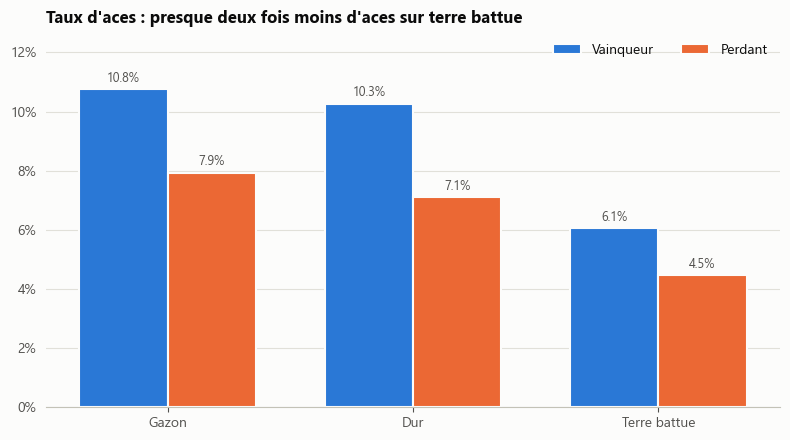

In [20]:
surface_labels = ["Gazon", "Dur", "Terre battue"]

def surface_chart(ind, title, filename):
    means = df_service.groupby("surface")[[f"w_{ind}", f"l_{ind}"]].mean().loc[SURFACES] * 100
    fig, ax = plt.subplots(figsize=(8, 4.5))
    winner_loser_bars(ax, surface_labels, means[f"w_{ind}"], means[f"l_{ind}"])
    ax.set_ylim(0, means.values.max() * 1.18)
    ax.set_title(title)
    ax.legend(loc="upper right", ncols=2)
    fig.tight_layout()
    fig.savefig(f"{IMG_DIR}/{filename}", dpi=150, bbox_inches="tight")
    plt.show()

surface_chart("ace_rate", "Taux d'aces : presque deux fois moins d'aces sur terre battue",
              "ace_rate_by_surface.png")

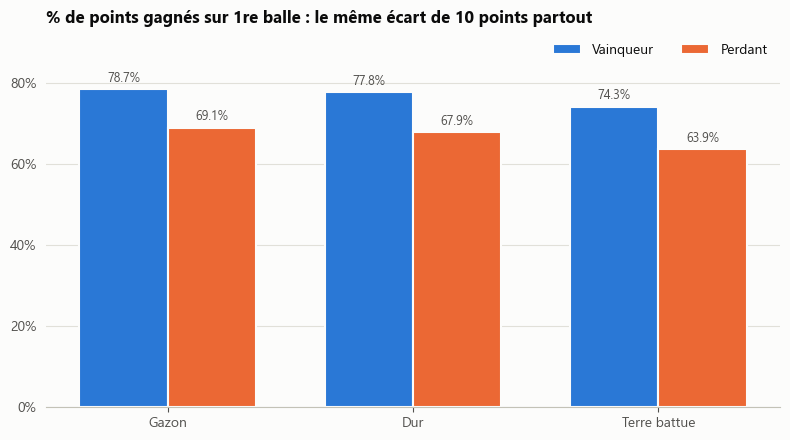

In [21]:
surface_chart("first_serve_win", "% de points gagnés sur 1re balle : le même écart de 10 points partout",
              "first_serve_win_by_surface.png")

**Interprétation**

- **Niveau : le gazon et le dur favorisent le service.** Le taux d'aces y est d'environ 9 %, contre 5 % sur terre battue. Le gazon donne le meilleur rendement sur 1re balle (73,9 %) et le plus de balles de break sauvées. La terre battue, plus lente avec un rebond plus haut, neutralise une partie de la puissance.
- **Pouvoir de distinction : il est presque identique sur les trois surfaces.** L'écart sur 1re balle est d'environ 10 points partout, et le vainqueur fait mieux sur la 1re balle dans environ 82 % des matchs, quelle que soit la surface.
- L'écart d'aces est deux fois plus faible sur terre (+1,6 pt contre +2,8 sur gazon et +3,2 sur dur), mais l'écart sur 1re balle reste le même : **sur terre, on gagne sa 1re balle par la qualité du coup suivant plutôt que par l'ace.**
- L'hypothèse « le service est plus décisif sur gazon » n'est donc **qu'à moitié vérifiée** : le service y rapporte plus de points, mais il ne départage pas mieux les joueurs que sur dur. Le classement des indicateurs reste le même : 1re balle, puis 2e balle, puis balles de break, puis aces.

## 6. Analyse 3 : les upsets

> Lorsqu'un joueur moins bien classé gagne, son service explique-t-il une partie de la surprise ?

Rappel : au tennis, un classement **plus petit** est **meilleur** (n° 5 > n° 50). Il y a donc upset quand `winner_rank > loser_rank`.

Les 12 matchs où l'un des deux classements manque sont exclus de cette partie.

In [22]:
df_rank = df_service.dropna(subset=["winner_rank", "loser_rank"]).copy()
df_rank["upset"] = df_rank["winner_rank"] > df_rank["loser_rank"]
df_rank["match_type"] = np.where(df_rank["upset"], "Upset", "Victoire du favori")

print(f"Matchs avec les deux classements : {len(df_rank)}")
print(f"Upsets                           : {df_rank['upset'].sum()} ({df_rank['upset'].mean():.1%})")
print()
print("Part d'upsets par surface :")
print((100 * df_rank.groupby("surface")["upset"].mean()).round(1).loc[SURFACES].to_string())

Matchs avec les deux classements : 2063
Upsets                           : 754 (36.5%)

Part d'upsets par surface :
surface
Grass   36.700
Hard    35.200
Clay    38.000


In [23]:
upset_cols = [f"{side}_{ind}" for ind in KEY_INDICATORS for side in ("w", "l")]
upset_table = (100 * df_rank.groupby("match_type")[upset_cols].mean()).T.round(1)
upset_table = upset_table[["Victoire du favori", "Upset"]]
upset_table.index = [
    f"{'Vainqueur' if col.startswith('w_') else 'Perdant'} - {INDICATORS[col[2:]]}"
    for col in upset_table.index
]
upset_table

match_type,Victoire du favori,Upset
Vainqueur - Taux d'aces,8.800,8.300
Perdant - Taux d'aces,5.800,6.800
Vainqueur - % pts gagnés 1re balle,76.900,75.900
Perdant - % pts gagnés 1re balle,65.700,67.900
Vainqueur - % pts gagnés 2e balle,56.800,55.800
Perdant - % pts gagnés 2e balle,45.300,47.500
Vainqueur - % balles de break sauvées,67.300,68.000
Perdant - % balles de break sauvées,52.000,52.000


In [24]:
# Chaque joueur sert-il mieux ou moins bien que d'habitude ?
# On compare son % de points gagnés sur 1re balle dans le match à sa moyenne de la saison.
long_fsw = pd.concat([
    df_service[["winner_id", "w_first_serve_win"]].set_axis(["player_id", "fsw"], axis=1),
    df_service[["loser_id", "l_first_serve_win"]].set_axis(["player_id", "fsw"], axis=1),
])
season_avg = long_fsw.groupby("player_id")["fsw"].mean()

df_rank["w_vs_usual"] = df_rank["w_first_serve_win"] - df_rank["winner_id"].map(season_avg)
df_rank["l_vs_usual"] = df_rank["l_first_serve_win"] - df_rank["loser_id"].map(season_avg)

(100 * df_rank.groupby("match_type")[["w_vs_usual", "l_vs_usual"]].mean()).round(1).rename(
    columns={"w_vs_usual": "Vainqueur vs sa moyenne (pts)", "l_vs_usual": "Perdant vs sa moyenne (pts)"}
)

,Vainqueur vs sa moyenne (pts),Perdant vs sa moyenne (pts)
match_type,,
Upset,4.500,-4.100
Victoire du favori,3.900,-4.200


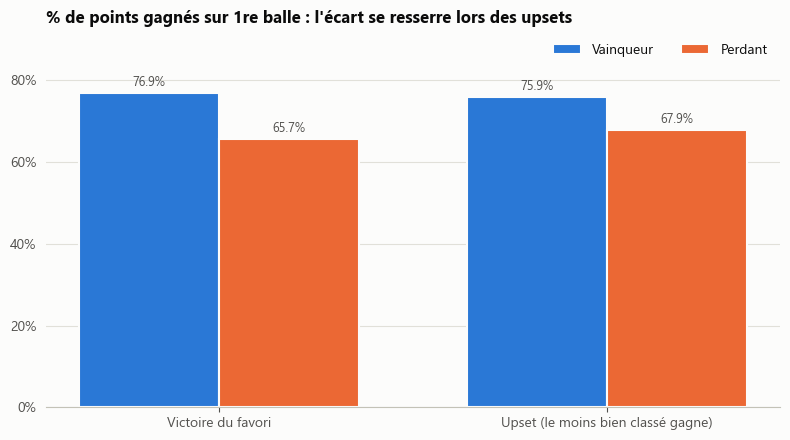

In [25]:
types = ["Victoire du favori", "Upset"]
means = df_rank.groupby("match_type")[["w_first_serve_win", "l_first_serve_win"]].mean().loc[types] * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
winner_loser_bars(ax, ["Victoire du favori", "Upset (le moins bien classé gagne)"],
                  means["w_first_serve_win"], means["l_first_serve_win"])
ax.set_ylim(0, 92)
ax.set_title("% de points gagnés sur 1re balle : l'écart se resserre lors des upsets")
ax.legend(loc="upper right", ncols=2)
fig.tight_layout()
fig.savefig(f"{IMG_DIR}/upsets_first_serve_win.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation**

- Les upsets sont fréquents : **36,5 % des matchs** (754 sur 2 063). C'est un peu plus sur terre battue (38 %) que sur dur (35 %). Attention, un n° 32 qui bat un n° 30 compte aussi comme un upset.
- Le vainqueur d'un upset sert **presque aussi bien** qu'un favori qui gagne (75,9 % contre 76,9 % sur 1re balle). Il ne réalise pas de performance « hors norme » au service.
- La différence vient du perdant : le favori battu garde un bon service (67,9 % contre 65,7 % pour un perdant classique). **L'écart au service se réduit donc de 11,2 à 8,0 points** lors des upsets.
- Par rapport à sa propre moyenne de la saison, le vainqueur d'un upset sert un peu au-dessus de son niveau (+4,5 pts, contre +3,9 pour un favori qui gagne). C'est un petit coup de pouce, pas l'explication principale.
- **Conclusion : le service explique une partie de la surprise, mais pas l'essentiel.** Les upsets se jouent plus souvent au retour, à l'échange ou sur quelques points importants. On le retrouve dans la partie suivante : le Serve Score désigne moins bien le vainqueur lors des upsets.

## 7. Serve Performance Score

Un **indicateur personnel et non officiel** qui résume la qualité du service d'un joueur dans un match en un seul chiffre.

```text
Serve Score = 0,4 × 1re balle gagnée + 0,3 × 2e balle gagnée + 0,2 × taux d'aces − 0,1 × taux de doubles fautes
```

**Mise à l'échelle.** Les quatre variables n'ont pas la même échelle (un ace rate de 8 % contre 77 % de points gagnés sur 1re balle). Chacune est donc **standardisée** (z-score) : `z = (valeur − moyenne) / écart-type`, en utilisant les valeurs de tous les joueurs (vainqueurs et perdants confondus). Un z-score de 0 correspond à un service moyen, +1 à un service supérieur d'un écart-type à la moyenne.

**Choix des poids.** Les poids reprennent le plan du projet et vont dans le sens de l'analyse 1 : la 1re balle compte le plus, puis la 2e. Ils sont **arbitraires**, et non optimisés.

Le score n'a pas de valeurs manquantes : les quatre variables sont définies pour tous les matchs (le taux de balles de break, qui peut être vide, n'est volontairement pas utilisé).

In [26]:
WEIGHTS = {
    "first_serve_win": 0.4,
    "second_serve_win": 0.3,
    "ace_rate": 0.2,
    "df_rate": -0.1,
}

df_service["winner_serve_score"] = 0.0
df_service["loser_serve_score"] = 0.0

for ind, weight in WEIGHTS.items():
    all_values = pd.concat([df_service[f"w_{ind}"], df_service[f"l_{ind}"]])
    mean, std = all_values.mean(), all_values.std()
    df_service["winner_serve_score"] += weight * (df_service[f"w_{ind}"] - mean) / std
    df_service["loser_serve_score"] += weight * (df_service[f"l_{ind}"] - mean) / std

print("Valeurs manquantes :", df_service[["winner_serve_score", "loser_serve_score"]].isna().sum().sum())
df_service[["winner_serve_score", "loser_serve_score"]].describe().T

Valeurs manquantes : 0


,count,mean,std,min,25%,50%,75%,max
winner_serve_score,2075.000,0.398,0.578,-1.186,0.002,0.365,0.762,2.910
loser_serve_score,2075.000,-0.398,0.600,-2.758,-0.792,-0.412,0.015,2.100


In [27]:
df_service["score_right"] = df_service["winner_serve_score"] > df_service["loser_serve_score"]
accuracy = df_service["score_right"].mean()
print(f"Accuracy du Serve Score : {accuracy:.1%}")
print()
print("Par surface :")
print((100 * df_service.groupby("surface")["score_right"].mean()).round(1).loc[SURFACES].to_string())
print()
print("Favori vs upset :")
df_rank["score_right"] = df_service.loc[df_rank.index, "score_right"]
print((100 * df_rank.groupby("match_type")["score_right"].mean()).round(1).to_string())

Accuracy du Serve Score : 88.0%

Par surface :
surface
Grass   87.300
Hard    87.900
Clay    88.200

Favori vs upset :
match_type
Upset                82.000
Victoire du favori   91.300


In [28]:
# Point de comparaison : le simple % de points gagnés au service
w_spw = (df_service["w_1stWon"] + df_service["w_2ndWon"]) / df_service["w_svpt"]
l_spw = (df_service["l_1stWon"] + df_service["l_2ndWon"]) / df_service["l_svpt"]
print(f"Le % de points gagnés au service désigne le vainqueur dans {(w_spw > l_spw).mean():.1%} des matchs")

Le % de points gagnés au service désigne le vainqueur dans 91.5% des matchs


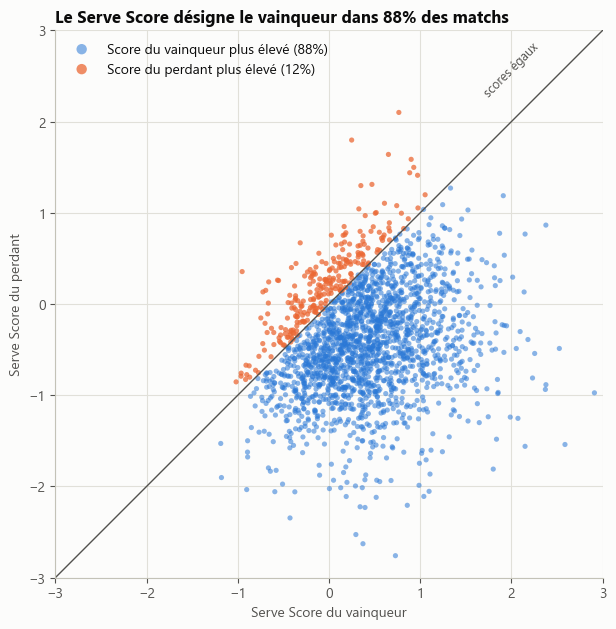

In [29]:
fig, ax = plt.subplots(figsize=(6.8, 6.4))
right = df_service[df_service["score_right"]]
wrong = df_service[~df_service["score_right"]]

ax.scatter(right["winner_serve_score"], right["loser_serve_score"], s=14, alpha=0.55,
           color=WINNER_COLOR, edgecolor="none",
           label=f"Score du vainqueur plus élevé ({len(right) / len(df_service):.0%})")
ax.scatter(wrong["winner_serve_score"], wrong["loser_serve_score"], s=14, alpha=0.75,
           color=LOSER_COLOR, edgecolor="none",
           label=f"Score du perdant plus élevé ({len(wrong) / len(df_service):.0%})")

lims = (-3, 3)
ax.plot(lims, lims, color=INK_SECONDARY, linewidth=1)
ax.text(2.0, 2.25, "scores égaux", rotation=45, color=INK_SECONDARY, fontsize=9,
        ha="center", va="bottom")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect("equal")
ax.grid(True, axis="both")
ax.spines["left"].set_visible(True)
ax.tick_params(axis="y", left=True)
ax.set_xlabel("Serve Score du vainqueur")
ax.set_ylabel("Serve Score du perdant")
ax.set_title(f"Le Serve Score désigne le vainqueur dans {accuracy:.0%} des matchs")
ax.legend(loc="upper left", markerscale=2)
fig.tight_layout()
fig.savefig(f"{IMG_DIR}/serve_score.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation**

- Le joueur au meilleur Serve Score gagne le match dans **88 % des cas**. Le score fonctionne aussi bien sur gazon, sur dur et sur terre (87–88 %), ce qui confirme que la surface change peu le rôle du service.
- Il est nettement moins fiable lors des **upsets (82 %)** que lors des victoires du favori (91 %) : le moins bien classé gagne plus souvent sans dominer au service.
- **Point d'honnêteté :** le simple pourcentage de points gagnés au service fait un peu mieux (91,5 %). Le score ne cherche pas à « prédire » : il **résume** le service avec des composantes lisibles (on sait si un joueur est bien noté grâce à ses aces ou grâce à sa 2e balle). Une partie de la perte de précision vient des poids donnés aux aces et aux doubles fautes, deux indicateurs qui distinguent peu le vainqueur (analyse 1).

## 8. Bonus : taille du joueur et aces

> Les joueurs plus grands réalisent-ils davantage d'aces ?

Le taux d'aces d'un seul match est très variable. On calcule donc un **taux d'aces sur toute la saison** par joueur (total d'aces / total de points au service) et on ne garde que les joueurs ayant **au moins 10 matchs** dans les données nettoyées. La taille vient de `atp_players.csv` (jointure `winner_id` / `loser_id` → `player_id`).

In [30]:
players = pd.read_csv(f"{DATA_DIR}/atp_players.csv")
players["name"] = players["name_first"] + " " + players["name_last"]
print(f"Joueurs dans le fichier : {len(players)}")
print(f"Taille manquante        : {players['height'].isna().mean():.0%}")

Joueurs dans le fichier : 61155
Taille manquante        : 95%


In [31]:
long = pd.concat([
    df_service[["winner_id", "w_ace", "w_svpt"]].set_axis(["player_id", "ace", "svpt"], axis=1),
    df_service[["loser_id", "l_ace", "l_svpt"]].set_axis(["player_id", "ace", "svpt"], axis=1),
])

player_stats = long.groupby("player_id").agg(matches=("ace", "size"), ace=("ace", "sum"), svpt=("svpt", "sum"))
player_stats["ace_rate"] = player_stats["ace"] / player_stats["svpt"]
player_stats = player_stats.join(players.set_index("player_id")[["name", "height"]])

print(f"Joueurs ayant joué en 2023        : {len(player_stats)}")
print(f"... dont taille manquante         : {player_stats['height'].isna().sum()}")

height_df = player_stats[(player_stats["matches"] >= 10) & player_stats["height"].notna()].copy()
print(f"Joueurs retenus (>= 10 matchs)    : {len(height_df)}")
height_df["height"].describe()

Joueurs ayant joué en 2023        : 289
... dont taille manquante         : 63
Joueurs retenus (>= 10 matchs)    : 118


count   118.000
mean    186.661
std       6.467
min     170.000
25%     183.000
50%     185.000
75%     191.000
max     206.000
Name: height, dtype: float64

In [32]:
# Pas de taille aberrante parmi les joueurs retenus (170 à 206 cm)
corr = height_df["height"].corr(height_df["ace_rate"])
slope, intercept = np.polyfit(height_df["height"], height_df["ace_rate"], 1)

print(f"Corrélation taille / taux d'aces : r = {corr:.2f}")
print(f"Pente : +{100 * slope:.2f} pt de taux d'aces par cm, soit +{1000 * slope:.1f} pts pour 10 cm")

bands = pd.cut(height_df["height"], [0, 180, 185, 190, 195, 250],
               labels=["≤ 180", "181-185", "186-190", "191-195", "> 195"])
(height_df.groupby(bands, observed=True)["ace_rate"].agg(["size", "mean"])
    .rename(columns={"size": "Joueurs", "mean": "Taux d'aces moyen"}))

Corrélation taille / taux d'aces : r = 0.67
Pente : +0.38 pt de taux d'aces par cm, soit +3.8 pts pour 10 cm


,Joueurs,Taux d'aces moyen
height,,
≤ 180,19,0.051
181-185,48,0.058
186-190,17,0.078
191-195,17,0.088
> 195,17,0.123


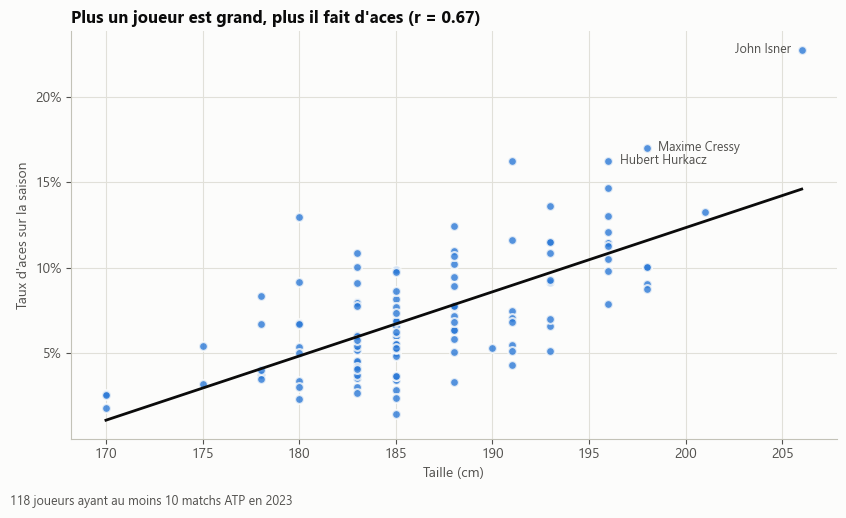

In [33]:
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(height_df["height"], 100 * height_df["ace_rate"], s=40, color=WINNER_COLOR,
           alpha=0.8, edgecolor=BACKGROUND, linewidth=1.5)

x_line = np.array([height_df["height"].min(), height_df["height"].max()])
ax.plot(x_line, 100 * (slope * x_line + intercept), color=INK, linewidth=2)

# On nomme uniquement les trois plus gros serveurs
for _, row in height_df.nlargest(3, "ace_rate").iterrows():
    at_right_edge = row["height"] > 203
    ax.annotate(row["name"], (row["height"], 100 * row["ace_rate"]),
                xytext=(-8, 0) if at_right_edge else (8, 0), textcoords="offset points",
                ha="right" if at_right_edge else "left", va="center", fontsize=9, color=INK_SECONDARY)

ax.grid(True, axis="both")
ax.spines["left"].set_visible(True)
ax.tick_params(axis="y", left=True)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_xlabel("Taille (cm)")
ax.set_ylabel("Taux d'aces sur la saison")
ax.set_title(f"Plus un joueur est grand, plus il fait d'aces (r = {corr:.2f})")
fig.text(0.01, -0.02, f"{len(height_df)} joueurs ayant au moins 10 matchs ATP en 2023",
         color=INK_SECONDARY, fontsize=9)
fig.tight_layout()
fig.savefig(f"{IMG_DIR}/height_vs_ace_rate.png", dpi=150, bbox_inches="tight")
plt.show()

**Interprétation**

- Le lien est **fort et net** : r = 0,67 sur 118 joueurs. Chaque tranche de 10 cm correspond à environ **+3,8 points** de taux d'aces.
- Les joueurs de plus de 1,95 m font en moyenne **12 % d'aces**, plus du double des joueurs de 1,80 m ou moins (5 %). Un point d'impact plus haut ouvre plus d'angles et permet de frapper plus fort sans faute.
- Mais l'analyse 1 a montré que **l'ace distingue peu le vainqueur**. Être grand aide à faire des aces, mais pas forcément à gagner les matchs : la 1re balle gagnée dépend aussi du placement et du coup suivant.

## 9. Conclusions

**1. Les vainqueurs présentent-ils de meilleures statistiques de service ?**
Oui, sur les six indicateurs. Les écarts sont nets sur l'efficacité (+10 points sur 1re et sur 2e balle, +15 points de balles de break sauvées) et faibles sur la régularité (+1,6 point de premières balles). Le vainqueur gagne plus de points sur son service dans 91,5 % des matchs : au niveau ATP, celui qui perd ses jeux de service perd presque toujours le match.

**2. Quel indicateur différencie le plus les vainqueurs des perdants ?**
Le **% de points gagnés sur 1re balle** : le vainqueur fait mieux dans 82 % des matchs. Viennent ensuite la 2e balle (77 %) et les balles de break sauvées (68 %). Les aces (63 %), le pourcentage de premières balles et les doubles fautes (56–57 %) comptent beaucoup moins. Pour un joueur, la leçon est claire : **ce n'est pas la quantité de premières balles qui fait gagner, c'est leur qualité**, ainsi que la solidité de la 2e balle.

**3. Quelle surface semble favoriser le plus le service ?**
**Le gazon**, suivi de près par le dur : plus d'aces (≈ 9 % contre 5 % sur terre), un meilleur rendement sur 1re balle et plus de balles de break sauvées. En revanche, la surface **ne change pas la hiérarchie** des indicateurs : sur les trois surfaces, le vainqueur gagne plus de points sur sa 1re balle dans environ 82 % des matchs. Le gazon rend le service plus payant pour tout le monde, mais pas plus décisif pour départager deux joueurs.

**4. Le service joue-t-il un rôle particulier lors des upsets ?**
Un rôle limité. Le joueur moins bien classé qui gagne sert à peu près comme un favori vainqueur, et seulement un peu au-dessus de sa moyenne. L'écart au service entre vainqueur et perdant se resserre (8 points sur 1re balle contre 11) et le Serve Score désigne moins bien le vainqueur (82 % contre 91 %). Les surprises se construisent davantage au retour et sur les points importants qu'au service.

**5. Le Serve Score permet-il de distinguer correctement le vainqueur ?**
Oui, dans **88 % des matchs**, de façon stable selon la surface. C'est un bon résumé lisible de la qualité du service. Il reste un indicateur personnel aux poids arbitraires : le simple % de points gagnés au service fait légèrement mieux (91,5 %). Donner plus de poids à la 2e balle et moins aux aces le rendrait plus cohérent avec les résultats de l'analyse 1.

**Limites**

- Une seule saison (2023), uniquement le circuit principal ATP.
- Les statistiques de service dépendent aussi de la qualité du retour adverse : on observe des associations, pas des causes.
- La définition de l'upset est stricte (un écart d'une place suffit).